# Recursos da estimação quântica de amplitude para o VaR

Estima tau_q(N) com um modelo analítico de recursos (etapas 2 e 3 da metodologia em `artigo.md`), sem simular o circuito. A carteira é a de `carteira.py`, a mesma do notebook clássico, e o erro-alvo é o mesmo: 1% do VaR.

**Algoritmo** (Woerner e Egger [4]). O operador A carrega a distribuição dos choques das N ações (N registradores de n qubits), calcula a perda da carteira num registrador acumulador e marca um qubit quando a perda é menor ou igual a um limiar x. A estimação de amplitude mede P(perda <= x), e uma busca binária em x encontra o quantil de 99%.

**Custo de cada parte**, em portas T, o recurso caro de um computador tolerante a falhas:

| Parte | Custo | Fonte |
|---|---|---|
| Carga genérica | 2^(N n) rotações | Grover-Rudolph; Herbert [8] mostra que esse custo elimina a vantagem |
| Carga com Cholesky | N normais (2^n rotações cada) + N(N+1)/2 multiplicações por constante | reparametrização por aritmética, como em Chakrabarti et al. [3] |
| Carga com fator único | N + 1 normais + N multiplicações | vale quando a correlação tem um fator, como na carteira sintética |
| Perda, linear por partes | por ação, s segmentos: s comparações e s funções afins | [4] |
| Perda, tabela | por ação, consulta a 2^n valores (QROM): 2^n Toffolis, mais um somador | Babbush et al., PRX 8, 041015 (2018) |
| Comparador com x | um somador de m bits | |
| Chamadas de Grover | pi / eps_a, com eps_a = f(VaR) x delta | estimação de amplitude canônica |
| Busca binária | log2(faixa da perda / delta) estimações | [4] |

O número de qubits por ação, n, é o menor que mantém o erro de discretização abaixo de metade do erro-alvo. Para a perda, o modelo usa a mais barata entre a aproximação linear por partes e a tabela.

**Premissas aritméticas.** Somador de b bits: 2b Toffolis (ripple-carry). Multiplicação de a bits por constante em b bits: a somadores. Toffoli: 7 portas T. Rotação sintetizada com erro 1e-13: cerca de 130 portas T (com erro 1e-10, o erro acumulado em ~1e9 rotações por estimação passaria de eps_a). O tempo supõe portas T executadas uma de cada vez, limitado pela produção de estados mágicos.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from carteira import ALPHA, K, montar_carteira, perda_por_acao, perdas
from scipy.special import ndtr

NS = [2**k for k in range(10)]
EPS = [0.01, 0.001]            # erro-alvo relativo do VaR: o do notebook clássico e um 10 vezes menor
FAIXA_Z = 4.0                  # a grade cobre +-4 desvios padrão
GUARDA = 3                     # bits extras na aritmética de ponto fixo
T_ROTACAO = 130                # portas T por rotação com erro 1e-13 (~3 log2(1/1e-13)); ~1e9 rotações por estimação
T_TOFFOLI = 7
FATOR_QAE = 1.0                # chamadas = FATOR_QAE * pi / eps_a; métodos iterativos têm constante maior
TAXAS_T = [1e4, 1e6, 1e8]      # portas T por segundo: de uma fábrica de estados mágicos a muito acima disso
M_REF = 2**17                  # cenários clássicos para medir VaR, densidade e faixa da perda

## Discretização

O circuito só vê a grade de 2^n valores por ação. Para N = 1, o VaR da distribuição discretizada é comparado com o contínuo, e n é o menor valor com erro abaixo de eps / 2.

In [2]:
def grade(n, faixa=FAIXA_Z):
    z = np.linspace(-faixa, faixa, 2**n)
    bordas = np.concatenate([[-np.inf], (z[1:] + z[:-1]) / 2, [np.inf]])
    return z, np.diff(ndtr(bordas))          # pontos e probabilidades de cada ponto


def var_discreto(z, p):
    L = perda_por_acao(z)
    ordem = np.argsort(L)
    return L[ordem][np.searchsorted(np.cumsum(p[ordem]), ALPHA)]


var_cont = var_discreto(*grade(21, faixa=8.0))     # referência: grade muito fina, praticamente contínua
erro_disc = {}
for n in range(4, 13):
    erro_disc[n] = var_discreto(*grade(n)) / var_cont - 1
    print(f"n={n}: VaR discreto / contínuo - 1 = {erro_disc[n]:+.3%}")
BITS = {eps: min(n for n, e in erro_disc.items() if abs(e) <= eps / 2) for eps in EPS}
print("qubits por ação:", BITS)

n=4: VaR discreto / contínuo - 1 = -14.755%
n=5: VaR discreto / contínuo - 1 = -10.251%
n=6: VaR discreto / contínuo - 1 = +1.476%
n=7: VaR discreto / contínuo - 1 = -1.293%
n=8: VaR discreto / contínuo - 1 = +0.135%
n=9: VaR discreto / contínuo - 1 = +0.382%
n=10: VaR discreto / contínuo - 1 = -0.194%
n=11: VaR discreto / contínuo - 1 = +0.044%
n=12: VaR discreto / contínuo - 1 = +0.073%
qubits por ação: {0.01: 8, 0.001: 11}


## Parâmetros do circuito para cada N

In [3]:
def segmentos(f_grade, tol):
    """Menor número de segmentos lineares uniformes com erro máximo <= tol na grade."""
    z = np.arange(len(f_grade))
    idx = z
    for s in range(1, len(z)):
        nos = np.unique(np.linspace(0, len(z) - 1, s + 1).round().astype(int))
        if np.abs(np.interp(idx, nos, f_grade[nos]) - f_grade).max() <= tol:
            return s
    return len(z) - 1


linhas = []
for N in NS:
    L = perdas(N, M_REF, "qmc", 0, montar_carteira(N))
    var = np.quantile(L, ALPHA)
    for eps in EPS:
        f_grade = perda_por_acao(grade(BITS[eps])[0])     # perda de uma ação em cada ponto da grade
        delta = eps * var
        h = 0.02 * var
        dens = np.mean(np.abs(L - var) <= h) / (2 * h)    # densidade da perda no VaR
        faixa = N * (f_grade.max() - f_grade.min())
        linhas.append({
            "N": N, "eps": eps, "var": var, "n": BITS[eps],
            "segmentos": segmentos(f_grade, delta / (4 * N)),       # N erros de aproximação somam <= delta/4
            "bits_acum": math.ceil(math.log2(faixa / (delta / (4 * N)))),
            "bissecoes": math.ceil(math.log2(faixa / delta)),
            "eps_a": dens * delta,
        })
par = pd.DataFrame(linhas)
par["chamadas_grover"] = np.ceil(FATOR_QAE * np.pi / par["eps_a"]).astype(int)
print(par.round(5).to_string(index=False))

  N   eps       var  n  segmentos  bits_acum  bissecoes   eps_a  chamadas_grover
  1 0.010   1.89728  8         37         11          9 0.00032             9863
  1 0.001   1.89728 11        108         14         12 0.00003            98629
  2 0.010   2.60110  8         43         12          9 0.00031            10105
  2 0.001   2.60110 11        137         16         13 0.00003           101050
  4 0.010   3.85194  8         51         14         10 0.00033             9633
  4 0.001   3.85194 11        158         17         13 0.00003            96322
  8 0.010   6.12044  8         64         15         10 0.00031            10044
  8 0.001   6.12044 11        171         18         13 0.00003           100433
 16 0.010  10.78553  8         64         16         10 0.00033             9521
 16 0.001  10.78553 11        187         19         13 0.00003            95209
 32 0.010  20.16992  8         64         17         10 0.00034             9359
 32 0.001  20.16992 11      

## Portas T e qubits

In [4]:
def somador(b):
    return 2 * b                                   # Toffolis


def mult(a, b):
    return a * somador(b)                          # registrador de a bits vezes constante, em b bits


def custo_grover(N, n, s, m):
    """Portas T de um operador de Grover (A e A dagger) para cada forma de carga, e qubits lógicos."""
    nx = n + GUARDA
    linear = s * (somador(nx) + mult(nx, m) + somador(m))         # por ação: comparações e afins
    tabela = 2**n + somador(m)                                    # por ação: consulta e soma no acumulador
    perda = N * min(linear, tabela)
    resto = T_TOFFOLI * (2 * perda + somador(m))                  # perda calculada e descalculada, comparador
    with np.errstate(over="ignore"):
        carga = {
            "generica": T_ROTACAO * np.float64(2.0) ** (N * n),
            "cholesky": T_ROTACAO * N * 2**n + T_TOFFOLI * N * (N + 1) / 2 * mult(n, nx),
            "fator unico": T_ROTACAO * (N + 1) * 2**n + T_TOFFOLI * 2 * N * mult(n, nx),
        }
    qubits = {"generica": N * n + 2 * m + 2, "cholesky": N * (n + nx) + 2 * m + 2,
              "fator unico": (N + 1) * n + N * nx + 2 * m + 2}
    return {c: (2 * (carga[c] + resto), qubits[c], carga[c] / (carga[c] + resto)) for c in carga}


tau_c = pd.read_csv("../dados/tau_c.csv")
melhor = tau_c.loc[tau_c.groupby("N")["tau_c_s"].idxmin()].set_index("N")   # melhor método clássico por N

linhas = []
for _, r in par.iterrows():
    # tau_c no erro-alvo eps: M escala como (eps / 1%)^(1 / inclinação) a partir do M medido
    tc = melhor.loc[r["N"], "tau_c_s"] * (r["eps"] / 0.01) ** (1 / melhor.loc[r["N"], "inclinacao_erro"])
    for carga, (t_grover, qubits, fracao) in custo_grover(r["N"], r["n"], r["segmentos"], r["bits_acum"]).items():
        t_total = r["bissecoes"] * r["chamadas_grover"] * t_grover
        linhas.append({"N": r["N"], "eps": r["eps"], "carga": carga, "qubits": qubits, "fracao_carga": fracao, "T_por_grover": t_grover,
                       "T_total": t_total, "tau_c_s": tc, "taxa_T_empate": t_total / tc,
                       **{f"tau_q_s_{t:.0e}": t_total / t for t in TAXAS_T}})
res = pd.DataFrame(linhas)
res.to_csv("../dados/tau_q.csv", index=False)
print(res[res["carga"] != "generica"][["N", "eps", "carga", "qubits", "fracao_carga", "T_total", "tau_c_s", "taxa_T_empate"]]
      .to_string(index=False, float_format=lambda x: f"{x:.3g}"))

  N   eps       carga   qubits  fracao_carga  T_total  tau_c_s  taxa_T_empate
  1  0.01    cholesky       43         0.895 6.85e+09  0.00047       1.46e+13
  1  0.01 fator unico       51         0.945  1.3e+10  0.00047       2.76e+13
  1 0.001    cholesky       55         0.902 7.05e+11  0.00493       1.43e+14
  1 0.001 fator unico       66         0.948 1.34e+12  0.00493       2.72e+14
  2  0.01    cholesky       64         0.898 1.42e+10  0.00261       5.45e+12
  2  0.01 fator unico       72         0.929 2.05e+10  0.00261       7.85e+12
  2 0.001    cholesky       84         0.902 1.57e+12   0.0436        3.6e+13
  2 0.001 fator unico       95         0.932 2.27e+12   0.0436       5.22e+13
  4  0.01    cholesky      106           0.9 3.11e+10   0.0195       1.59e+12
  4  0.01 fator unico      114         0.916 3.71e+10   0.0195        1.9e+12
  4 0.001    cholesky      136         0.903 3.01e+12     1.62       1.86e+12
  4 0.001 fator unico      147          0.92 3.67e+12     1.62  

/var/folders/kj/z1g45h2x5nqd5l3t4b9lfnzc0000gn/T/ipykernel_61305/3166499116.py:24: RuntimeWarning: invalid value encountered in scalar divide
  return {c: (2 * (carga[c] + resto), qubits[c], carga[c] / (carga[c] + resto)) for c in carga}


## Quão rápido o hardware precisa ser

`taxa_T_empate` é a taxa de portas T por segundo que deixaria tau_q igual a tau_c. Acima dela, o quântico entrega o VaR antes do clássico. As linhas horizontais são as taxas dos cenários.

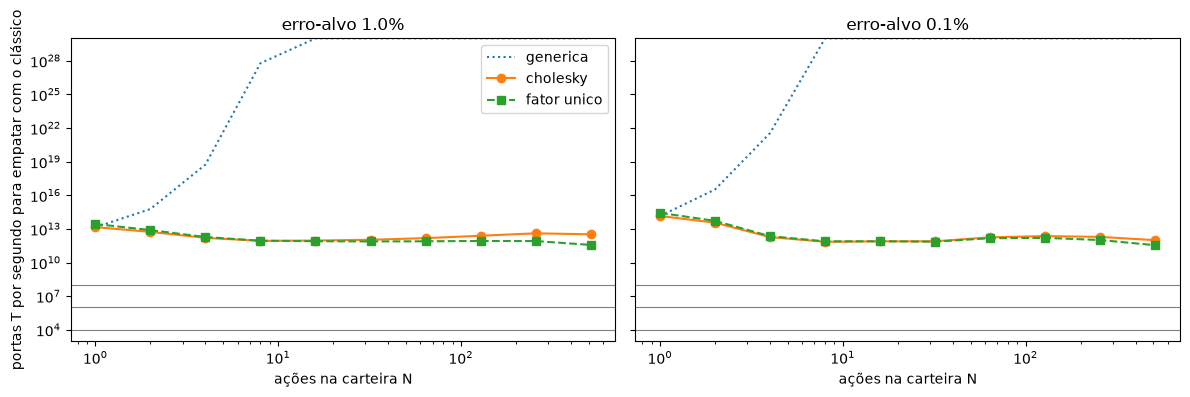

1e+04 T/s: vantagem em 0 de 60 combinações 
1e+06 T/s: vantagem em 0 de 60 combinações 
1e+08 T/s: vantagem em 0 de 60 combinações 


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, eps in zip(ax, EPS):
    for carga, estilo in (("generica", ":"), ("cholesky", "o-"), ("fator unico", "s--")):
        g = res[(res["eps"] == eps) & (res["carga"] == carga)]
        a.loglog(g["N"], g["taxa_T_empate"].clip(upper=1e30), estilo, label=carga)
    for t in TAXAS_T:
        a.axhline(t, color="gray", lw=0.8)
    a.set(xlabel="ações na carteira N", title=f"erro-alvo {eps:.1%}", ylim=(1e3, 1e30))
ax[0].set_ylabel("portas T por segundo para empatar com o clássico")
ax[0].legend()
plt.tight_layout()
plt.savefig("../figuras/var_quantico_taxa.png", dpi=150)
plt.show()

for t in TAXAS_T:
    v = res[res[f"tau_q_s_{t:.0e}"] < res["tau_c_s"]]
    print(f"{t:.0e} T/s: vantagem em {len(v)} de {len(res)} combinações",
          "" if v.empty else v[["N", "eps", "carga"]].to_dict("records"))

## O que observar

- Com carga genérica, o custo explode com N, como Herbert [8] mostra: a vantagem, se existir, some em N muito pequeno.
- Com Cholesky, a carga cresce com N^2, enquanto o clássico cresce com N. É o mecanismo da H1, agora com uma taxa de hardware para cada N.
- Diminuir o erro-alvo favorece o quântico: o clássico cresce com 1/eps^2 e o quântico com 1/eps.
- Todos os números dependem das premissas listadas no início. As constantes são aproximações de ordem de grandeza, e a conversão para tempo deve ser refeita com um estimador de recursos [11].